# Systémy hromadné obsluhy

*Nad rámec cvičení — kapitola 7 skripta.*

---

Fronta u pokladny, požadavky na server, pacienti v čekárně, pakety v routeru. Společné schéma: **požadavky přicházejí náhodně, obsluha trvá náhodně dlouho, a mezi tím se čeká**.

Model je blízký příbuzný pojišťovny ze cvičení 2 a 9 — tam taky přicházely požadavky v náhodných okamžicích. Rozdíl je, že teď nás nezajímá jen součet, ale **časový průběh**: kolik lidí ve frontě stojí a jak dlouho čekají.

- model **M/M/1** a co znamenají ta tři písmena
- dva způsoby simulace: **model typu $\Delta t$** a **model diskrétních událostí** — a proč je druhý lepší
- ověření proti přesným vzorcům
- co se děje, když se zatížení blíží jedné
- **přechodový jev**: proč se začátek běhu musí zahodit

In [1]:
import heapq
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # opakovatelné výsledky


def exponential(lam):
    return -math.log(1.0 - random.random()) / lam

## 1. Model M/M/1

Značení **A/B/c** (Kendall): A = příchody, B = obsluha, c = počet linek.

**M/M/1** znamená:

- **M**arkovské příchody: mezery mezi příchody jsou $\operatorname{Exp}(\lambda)$, tedy příchody tvoří Poissonův proces s intenzitou $\lambda$ (cvičení 3),
- **M**arkovská obsluha: doba obsluhy je $\operatorname{Exp}(\mu)$,
- **1** linka, fronta neomezená, obsluhuje se v pořadí příchodu (FIFO).

Klíčový parametr je **zatížení**

$$\varrho = \frac{\lambda}{\mu}.$$

Pro $\varrho \ge 1$ přichází práce rychleji, než se stíhá odbavovat, a fronta roste nade všechny meze. Pro $\varrho < 1$ se systém ustálí a platí přesné vzorce:

| Veličina | Vzorec |
|---|---|
| $P(n \text{ požadavků v systému})$ | $(1-\varrho)\varrho^{\,n}$ |
| střední počet v systému $L$ | $\dfrac{\varrho}{1-\varrho}$ |
| střední počet ve frontě $L_q$ | $\dfrac{\varrho^2}{1-\varrho}$ |
| střední doba v systému $W$ | $\dfrac{1}{\mu - \lambda}$ |
| střední doba čekání $W_q$ | $\dfrac{\varrho}{\mu - \lambda}$ |

Platí také **Littleova věta** $L = \lambda W$, která se hodí jako nezávislá kontrola.

Právě to, že přesné vzorce známe, dělá z M/M/1 ideální zkušební úlohu: simulaci máme s čím porovnat.

In [2]:
def teorie_mm1(lam, mu):
    rho = lam / mu
    return dict(rho=rho, L=rho / (1 - rho), Lq=rho**2 / (1 - rho),
                W=1 / (mu - lam), Wq=rho / (mu - lam))


for lam, mu in ((0.5, 1.0), (0.8, 1.0), (0.95, 1.0)):
    t = teorie_mm1(lam, mu)
    print(f"λ = {lam}, μ = {mu}:  ϱ = {t['rho']:.2f}   L = {t['L']:6.2f}   W = {t['W']:6.2f}   Wq = {t['Wq']:6.2f}")

λ = 0.5, μ = 1.0:  ϱ = 0.50   L =   1.00   W =   2.00   Wq =   1.00
λ = 0.8, μ = 1.0:  ϱ = 0.80   L =   4.00   W =   5.00   Wq =   4.00
λ = 0.95, μ = 1.0:  ϱ = 0.95   L =  19.00   W =  20.00   Wq =  19.00


## 2. Dva způsoby, jak takový systém simulovat

### Model typu $\Delta t$

Nejpřímočařejší nápad: krájet čas na krátké úseky $\Delta t$ a v každém se zeptat, co se stalo. S pravděpodobností $\lambda\Delta t$ přijde požadavek, s pravděpodobností $\mu\Delta t$ se dokončí obsluha.

Je to tentýž postup, jakým cvičení 2 krájelo rok na dny. A má stejné dvě vady:

- **Je nepřesný.** V jednom $\Delta t$ se může stát víc událostí, ale model připustí nejvýš jednu. Chyba mizí až s $\Delta t \to 0$.
- **Je pomalý.** Většina kroků je prázdná; čím menší $\Delta t$, tím víc prázdných kroků.

### Model diskrétních událostí

Lepší nápad: čas **neplyne**, ale skáče. Vedeme si seznam naplánovaných událostí, vždy vyndáme tu nejbližší, posuneme na ni hodiny a zpracujeme ji. Mezi událostmi se nic neděje, takže není co počítat.

Pro M/M/1 stačí dva typy událostí: *příchod* a *odchod*. Model je **přesný** (žádná diskretizace) a dělá právě tolik kroků, kolik je událostí.

Napíšeme oba a porovnáme.

In [3]:
def fronta_delta_t(lam, mu, T, dt):
    """Model typu Δt: v každém kroku nanejvýš jeden příchod a nanejvýš jeden odchod."""
    n = 0
    soucet_n = 0.0
    kroku = int(T / dt)
    for _ in range(kroku):
        if n > 0 and random.random() < mu * dt:
            n -= 1
        if random.random() < lam * dt:
            n += 1
        soucet_n += n * dt
    return soucet_n / (kroku * dt)        # časový průměr počtu v systému = L


def fronta_udalosti(lam, mu, T, zahrivani=0.0):
    """Model diskrétních událostí pro M/M/1.

    Vrací (L, Lq, W, Wq, P(n), využití linky). Část běhu do času `zahrivani`
    se do statistik nezapočítá — viz oddíl o přechodovém jevu.
    """
    t = 0.0
    n = 0                                    # počet v systému
    udalosti = [(exponential(lam), "prichod")]
    ve_fronte = []                           # časy příchodu čekajících
    doby_v_systemu = []
    cas_v_stavu = {}
    posledni = 0.0

    while udalosti:
        cas, typ = heapq.heappop(udalosti)
        if cas > T:
            break
        if cas > zahrivani:                  # započítej dobu strávenou ve stavu n
            od = max(posledni, zahrivani)
            cas_v_stavu[n] = cas_v_stavu.get(n, 0.0) + (cas - od)
        posledni = cas
        t = cas

        if typ == "prichod":
            n += 1
            ve_fronte.append(t)
            heapq.heappush(udalosti, (t + exponential(lam), "prichod"))
            if n == 1:                       # linka byla volná, začni hned obsluhovat
                heapq.heappush(udalosti, (t + exponential(mu), "odchod"))
        else:
            n -= 1
            prisel = ve_fronte.pop(0)
            if t > zahrivani:
                doby_v_systemu.append(t - prisel)
            if n > 0:
                heapq.heappush(udalosti, (t + exponential(mu), "odchod"))

    celkem = sum(cas_v_stavu.values())
    P = {k: v / celkem for k, v in sorted(cas_v_stavu.items())}
    L = sum(k * p for k, p in P.items())
    Lq = sum(max(k - 1, 0) * p for k, p in P.items())
    W = sum(doby_v_systemu) / len(doby_v_systemu)
    return L, Lq, W, W - 1 / mu, P, 1 - P.get(0, 0.0)


lam, mu, T = 0.8, 1.0, 200_000.0
t = teorie_mm1(lam, mu)
L, Lq, W, Wq, P, vyuziti = fronta_udalosti(lam, mu, T, zahrivani=1000.0)

print(f"M/M/1 s λ = {lam}, μ = {mu} (ϱ = {t['rho']}), délka běhu T = {T:,.0f}".replace(",", " "))
print(f"\n{'veličina':28s} {'simulace':>10s} {'teorie':>10s}")
print(f"{'L  (počet v systému)':28s} {L:>10.4f} {t['L']:>10.4f}")
print(f"{'Lq (počet ve frontě)':28s} {Lq:>10.4f} {t['Lq']:>10.4f}")
print(f"{'W  (doba v systému)':28s} {W:>10.4f} {t['W']:>10.4f}")
print(f"{'Wq (doba čekání)':28s} {Wq:>10.4f} {t['Wq']:>10.4f}")
print(f"{'využití linky':28s} {vyuziti:>10.4f} {t['rho']:>10.4f}")
print(f"\nLittleova věta: L = λW ?   {L:.4f}  vs  {lam * W:.4f}")

M/M/1 s λ = 0.8  μ = 1.0 (ϱ = 0.8)  délka běhu T = 200 000

veličina                       simulace     teorie
L  (počet v systému)             3.8340     4.0000
Lq (počet ve frontě)             3.0368     3.2000
W  (doba v systému)              4.8034     5.0000
Wq (doba čekání)                 3.8034     4.0000
využití linky                    0.7973     0.8000

Littleova věta: L = λW ?   3.8340  vs  3.8427


Simulace sedí na všech pět vzorců a Littleova věta platí. Teď srovnání s modelem typu $\Delta t$.

In [4]:
import time

presne_L = t["L"]
OPAK, T_KRATKY = 12, 20_000.0

print("Chybu modelu Δt tvoří dvě části: systematické zkreslení z diskretizace")
print("a statistický šum. Oddělíme je průměrem z několika nezávislých běhů.\n")
print(f"{'metoda':24s} {'L (průměr)':>12s} {'sm. chyba':>11s} {'zkreslení':>11s} {'čas':>8s}")

dts, zkresleni, chyby_se = [], [], []
for dt in (0.5, 0.25, 0.1, 0.05):
    t0 = time.perf_counter()
    vysl = [fronta_delta_t(lam, mu, T_KRATKY, dt) for _ in range(OPAK)]
    cas = (time.perf_counter() - t0)
    m = sum(vysl) / OPAK
    se = math.sqrt(sum((v - m) ** 2 for v in vysl) / (OPAK - 1) / OPAK)
    dts.append(dt); zkresleni.append(abs(m - presne_L)); chyby_se.append(se)
    print(f"{'Δt = ' + format(dt, '.2f'):24s} {m:>12.3f} {se:>11.3f} {m - presne_L:>+11.3f} {cas:>7.1f} s")

t0 = time.perf_counter()
vysl = [fronta_udalosti(lam, mu, T_KRATKY, zahrivani=500.0)[0] for _ in range(OPAK)]
cas_ud = time.perf_counter() - t0
m_ud = sum(vysl) / OPAK
se_ud = math.sqrt(sum((v - m_ud) ** 2 for v in vysl) / (OPAK - 1) / OPAK)
print(f"{'diskrétní události':24s} {m_ud:>12.3f} {se_ud:>11.3f} {m_ud - presne_L:>+11.3f} {cas_ud:>7.1f} s")
print(f"{'teorie':24s} {presne_L:>12.3f}")
print(f"\nmodel Δt zkresluje dolů: v jednom kroku připustí nanejvýš jeden příchod")
print(f"a jeden odchod, takže špičky fronty ořezává. Model událostí zkreslení nemá —")
print(f"jeho odchylka ({m_ud - presne_L:+.3f}) je v rámci směrodatné chyby ({se_ud:.3f}).")

Chybu modelu Δt tvoří dvě části: systematické zkreslení z diskretizace
a statistický šum. Oddělíme je průměrem z několika nezávislých běhů.

metoda                     L (průměr)   sm. chyba   zkreslení      čas
Δt = 0.50                       2.471       0.053      -1.529     0.1 s
Δt = 0.25                       3.122       0.081      -0.878     0.1 s
Δt = 0.10                       3.633       0.095      -0.367     0.2 s
Δt = 0.05                       3.839       0.055      -0.161     0.4 s
diskrétní události              4.134       0.123      +0.134     0.1 s
teorie                          4.000

model Δt zkresluje dolů: v jednom kroku připustí nanejvýš jeden příchod
a jeden odchod, takže špičky fronty ořezává. Model událostí zkreslení nemá —
jeho odchylka (+0.134) je v rámci směrodatné chyby (0.123).


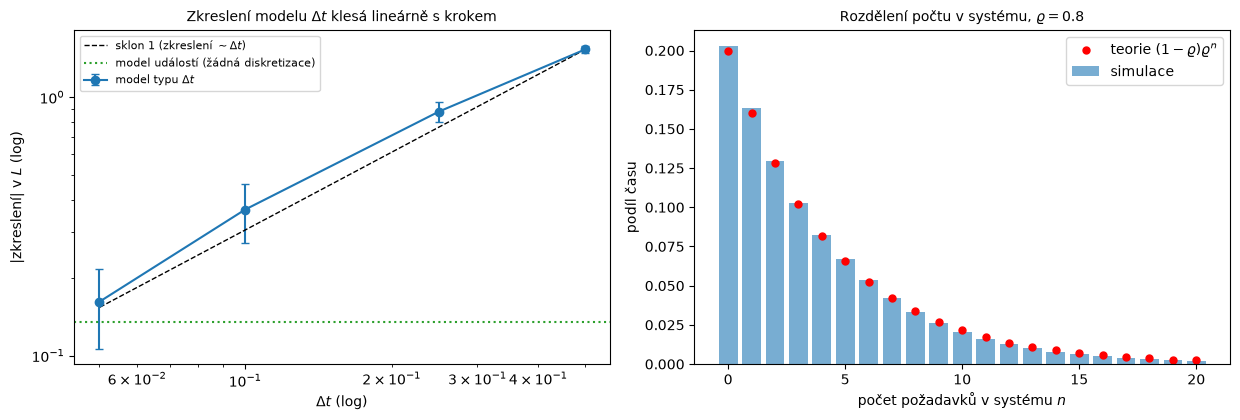

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

ax = axes[0]
ax.errorbar(dts, zkresleni, yerr=chyby_se, fmt="o-", capsize=3, label="model typu $\\Delta t$")
ax.loglog(dts, [zkresleni[0] * (d / dts[0]) for d in dts], "k--", lw=1,
          label="sklon 1 (zkreslení $\\sim \\Delta t$)")
ax.axhline(abs(m_ud - presne_L), color="tab:green", ls=":",
           label="model událostí (žádná diskretizace)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("$\\Delta t$ (log)")
ax.set_ylabel("$|$zkreslení$|$ v $L$ (log)")
ax.set_title("Zkreslení modelu $\\Delta t$ klesá lineárně s krokem", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
ks = sorted(k for k in P if k <= 20)
ax.bar(ks, [P[k] for k in ks], alpha=0.6, label="simulace")
rho = t["rho"]
ax.plot(ks, [(1 - rho) * rho**k for k in ks], "ro", ms=5, label=r"teorie $(1-\varrho)\varrho^n$")
ax.set_xlabel("počet požadavků v systému $n$")
ax.set_ylabel("podíl času")
ax.set_title(f"Rozdělení počtu v systému, $\\varrho = {rho}$", fontsize=10)
ax.legend()

plt.tight_layout()
plt.show()

Levý graf potvrzuje, co se čekalo: **zkreslení** modelu $\Delta t$ klesá lineárně s krokem. Zároveň je vidět, proč se vyplatilo oddělit ho od šumu — při $\Delta t = 0.05$ je už zkreslení menší než statistická chyba jednoho běhu, takže z jediného běhu by nebylo poznat.

Model diskrétních událostí žádné zkreslení nemá (jeho odchylka je v rámci směrodatné chyby) a běží přitom rychleji než model $\Delta t$ s jemným krokem. Lepší v obou ohledech zároveň — proto se v praxi používá skoro výhradně.

Pravý graf ukazuje, že i celé **rozdělení** sedí, ne jen střední hodnoty.

## 3. Když se zatížení blíží jedné

Vzorec $L = \varrho/(1-\varrho)$ má ve jmenovateli $1 - \varrho$, takže pro $\varrho \to 1$ roste nade všechny meze. To není matematická kuriozita, ale provozní realita: **systém využitý na 95 % má desetkrát delší frontu než systém využitý na 90 %**.

Zároveň je to pro simulaci nepříjemné — čím blíž k jedničce, tím pomaleji se průměry ustalují, jak uvidíme na pravém grafu níž.

     ϱ   L simulace   L teorie  rel. chyba
  0.50        0.997      1.000       0.3%
  0.70        2.377      2.333       1.9%
  0.80        4.054      4.000       1.3%
  0.90        8.709      9.000       3.2%
  0.95       19.421     19.000       2.2%


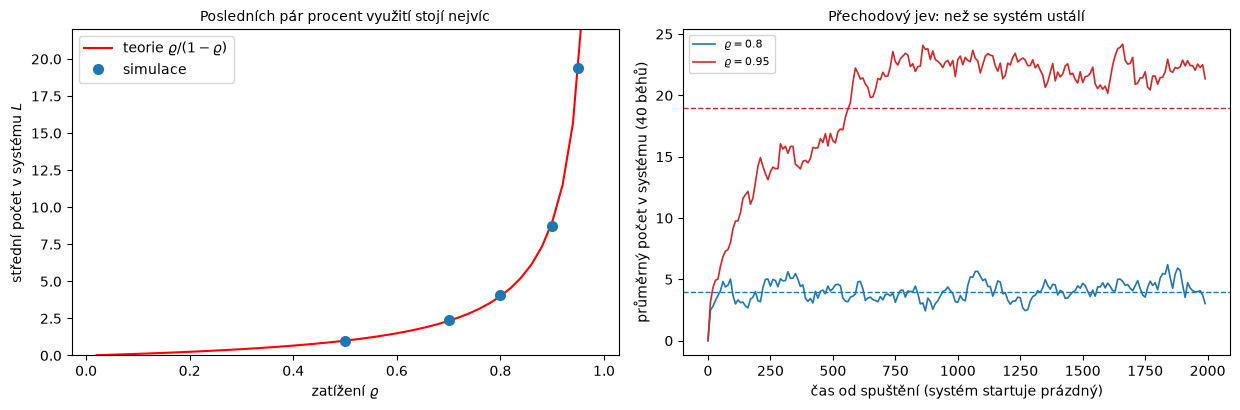

In [6]:
rhos = (0.5, 0.7, 0.8, 0.9, 0.95)
L_sim, L_teor = [], []
print(f"{'ϱ':>6s} {'L simulace':>12s} {'L teorie':>10s} {'rel. chyba':>11s}")
for rho in rhos:
    lam_ = rho
    Lx = fronta_udalosti(lam_, 1.0, 300_000.0, zahrivani=5000.0)[0]
    Lt = rho / (1 - rho)
    L_sim.append(Lx); L_teor.append(Lt)
    print(f"{rho:>6.2f} {Lx:>12.3f} {Lt:>10.3f} {abs(Lx - Lt) / Lt:>10.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

ax = axes[0]
jemne = [0.02 * i for i in range(1, 50)]
ax.plot(jemne, [r / (1 - r) for r in jemne], "r-", label=r"teorie $\varrho/(1-\varrho)$")
ax.plot(rhos, L_sim, "o", ms=7, label="simulace")
ax.set_xlabel(r"zatížení $\varrho$")
ax.set_ylabel("střední počet v systému $L$")
ax.set_ylim(0, 22)
ax.set_title("Posledních pár procent využití stojí nejvíc", fontsize=10)
ax.legend()

# přechodový jev: průběh od prázdného systému
ax = axes[1]
for rho, barva in ((0.8, "tab:blue"), (0.95, "tab:red")):
    behy = []
    for _ in range(40):
        prubeh = []
        t_, n, udalosti, nasl = 0.0, 0, [(exponential(rho), "p")], 0.0
        vzorky = []
        while t_ < 2000:
            cas, typ = heapq.heappop(udalosti)
            while nasl < cas and nasl < 2000:
                vzorky.append(n); nasl += 10.0
            t_ = cas
            if typ == "p":
                n += 1
                heapq.heappush(udalosti, (t_ + exponential(rho), "p"))
                if n == 1:
                    heapq.heappush(udalosti, (t_ + exponential(1.0), "o"))
            else:
                n -= 1
                if n > 0:
                    heapq.heappush(udalosti, (t_ + exponential(1.0), "o"))
        behy.append(vzorky)
    delka = min(len(b) for b in behy)
    prumer = [sum(b[i] for b in behy) / len(behy) for i in range(delka)]
    ax.plot([10 * i for i in range(delka)], prumer, color=barva, lw=1.2, label=f"$\\varrho = {rho}$")
    ax.axhline(rho / (1 - rho), color=barva, ls="--", lw=1)
ax.set_xlabel("čas od spuštění (systém startuje prázdný)")
ax.set_ylabel("průměrný počet v systému (40 běhů)")
ax.set_title("Přechodový jev: než se systém ustálí", fontsize=10)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

Pravý graf je důvod, proč má `fronta_udalosti` parametr `zahrivani`. Simulace startuje z **prázdného** systému, což není typický stav — chvíli trvá, než se fronta naplní na ustálenou úroveň. Kdybychom průměrovali od času nula, podhodnotili bychom $L$.

A čím blíž je $\varrho$ k jedničce, tím déle to trvá: při $\varrho = 0.8$ stačí pár stovek časových jednotek, při $\varrho = 0.95$ ani dva tisíce nestačí.

Tomu se říká **přechodový jev** (warm-up) a řeší se zahozením začátku běhu. Souvisí to přímo se závislými vzorky ze sešitu `ch01_05_kdy_se_mc_vyplati`: po sobě jdoucí stavy fronty jsou silně korelované, takže ani chybovou úsečku nelze počítat naivně — patří sem průměry po blocích.

## Shrnutí

| Pojem | Co si pamatovat |
|-------|-----------------|
| M/M/1 | exponenciální příchody i obsluha, jedna linka, neomezená fronta |
| Zatížení $\varrho = \lambda/\mu$ | pro $\varrho \ge 1$ fronta roste nade všechny meze |
| Model typu $\Delta t$ | jednoduchý, ale chyba $\sim \Delta t$ a spousta prázdných kroků |
| Model diskrétních událostí | čas skáče na další událost; **přesný i rychlejší** |
| Littleova věta | $L = \lambda W$ — nezávislá kontrola správnosti simulace |
| $L = \varrho/(1-\varrho)$ | u vysokého využití roste fronta explozivně |
| Přechodový jev | start z prázdna není typický stav; začátek běhu zahoďte |
| Závislost vzorků | stavy fronty jsou korelované ⟹ chybu počítejte po blocích |

### Zkuste si

1. Změňte obsluhu na konstantní (model M/D/1). Teorie dává $L_q = \varrho^2/(2(1-\varrho))$ — ověřte. Proč je fronta kratší než u M/M/1?
2. Přidejte druhou linku (M/M/2) a porovnejte s dvěma oddělenými M/M/1 frontami, každou s poloviční intenzitou. Která varianta čeká kratší dobu a proč?
3. Omezte frontu na $K$ míst a měřte podíl odmítnutých požadavků (Erlangův vzorec).
4. Zaveďte prioritu: požadavky dvou tříd, jedna se obsluhuje přednostně. Jak se změní $W$ pro každou třídu a jak jejich vážený průměr?
5. Změřte, jak dlouhé zahřívání je potřeba pro $\varrho = 0.99$, a porovnejte s $\varrho = 0.8$.
6. Spočítejte chybovou úsečku pro $L$ metodou průměrů po blocích a porovnejte s naivním vzorcem $\sigma/\sqrt{N}$.